In [2]:
%matplotlib inline
from matplotlib import rcParams
import matplotlib.pyplot as plt

# Introduction to Ensemble Methods

Ensemble methods are techniques for obtaining better predictive performances by using multiple models.

To get an overview of the methods we are going to see today, you can watch this video of Machine learnia about Ensemble learning : https://www.youtube.com/watch?v=7C_YpudYtw8 (you don't need to understand everything before beginning the notebook ;)).

The following dataset comes from a bank which would like to know when a new client arrives if this client will subscribe to a long term deposit.

The bank will be considered as your client in the following parts.

---

**Feel free to create sklearn Pipelines for simplifying the following experiments** 

## Introducing and exploring the dataset

The dataset is located in `../data/bank-full.csv`. It has 17 columns, the target column or $ŷ$ is the column named `y`.

Columns summary  : 

| column name | simple description |
|-------------|------------------------|
| age | age |
| job | type of job |
| marital | marital status |
| education | education level |
| default | has credit in default? |
| balance | average yearly balance, in euros  |
| housing | has housing loan? |
| loan | has personal loan? |
| contact | contact communication |
| month | last contact month of year |
| day_of_week | last contact day of the week |
| duration |  last contact duration in seconds |
| campaign |  number of contacts performed during campaign for this client |
| pday | number of days that passed by after the client was last contacted from a previous campaign (-1 means client was not previously contacted) |
| previous | number of contacts performed before this campaign and for this client |
| poutcome | outcome of the previous marketing campaign |
| **output :** |  |
| y | has  the client subscribed a term deposit? |

Let's explore the dataset a bit using pandas.

While exploring the dataset it is recommended to create a list of categorical features

In [3]:
import pandas as pd

Create a dataframe with the dataset `../data/bank-full.csv`

In [4]:
# code here
dataset = pd.read_csv('../data/bank-full.csv', sep=";", encoding="utf-8")


dataset.info()
dataset.describe()


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


Describe the dataset informations

In [5]:
# code here
dataset.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


Use histogramms to display the features' distribution

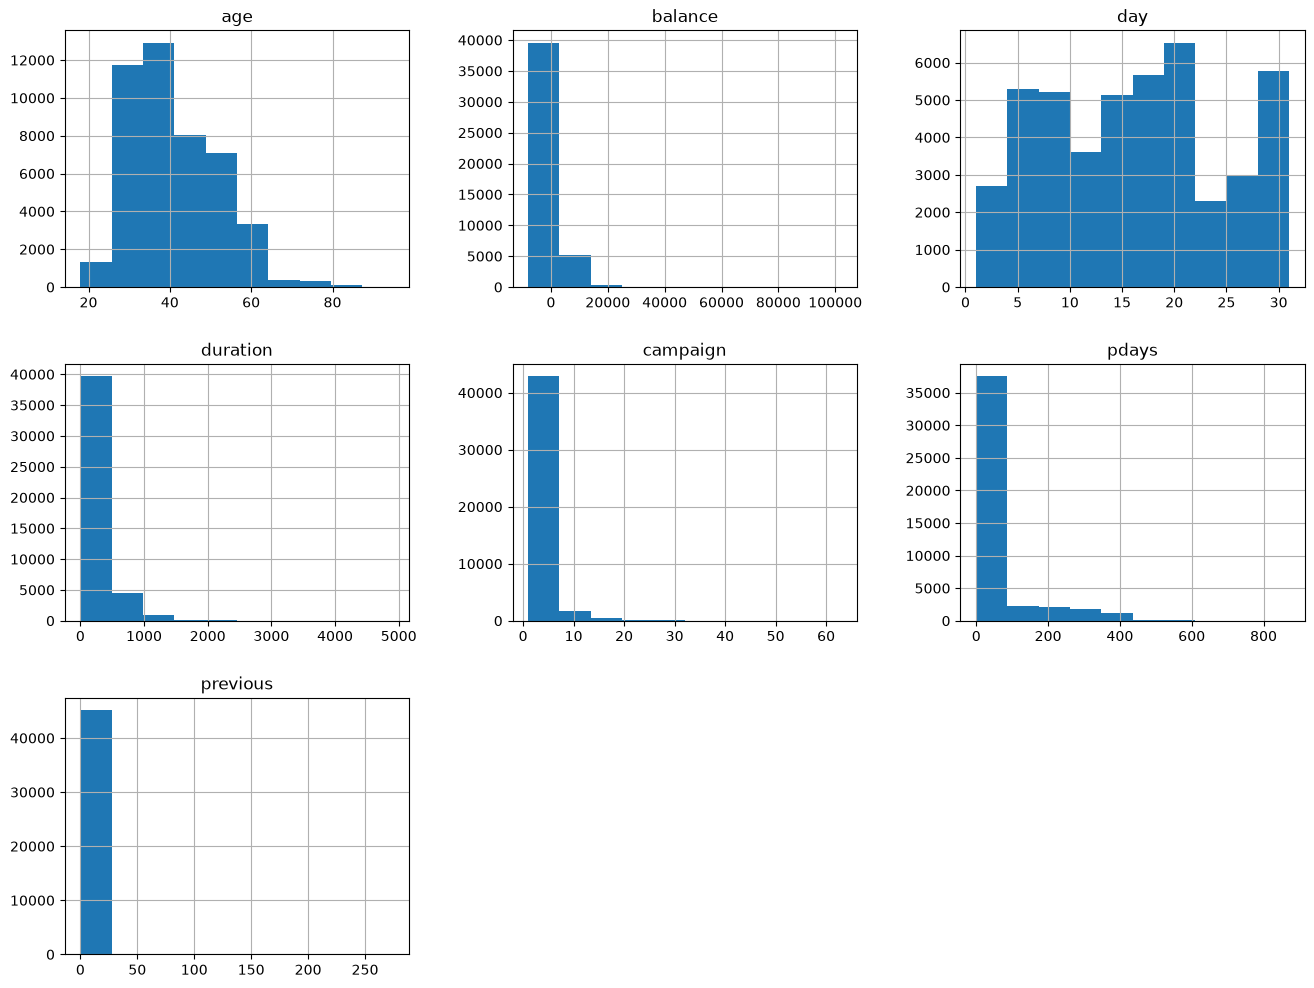

(45211, 17)


In [6]:
# code here
rcParams['figure.figsize'] = 16,12
plots = dataset.hist()
plt.show()

print(dataset.shape)

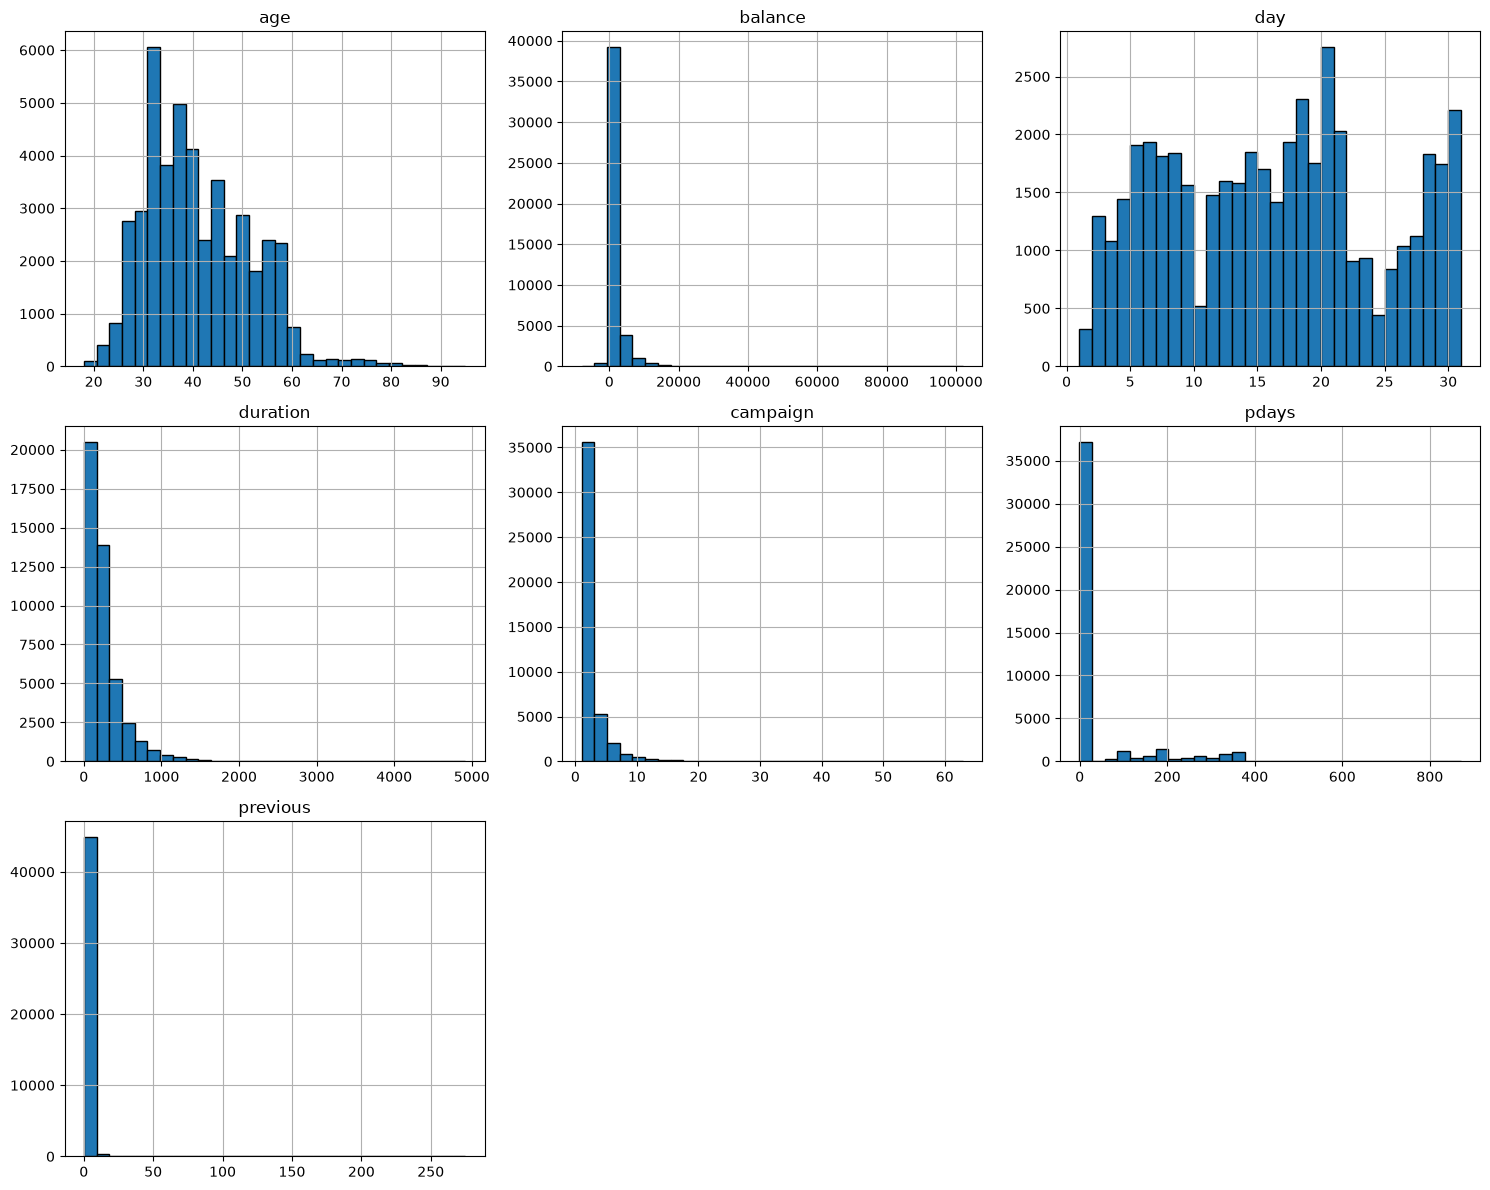

In [7]:
## El mismo histograma pero solo con columnas numericas

# Seleccionar columnas numéricas
numerical_features = dataset.select_dtypes(include=['int64', 'float64'])

# Mostrar histogramas
numerical_features.hist(figsize=(15, 12), bins=30, edgecolor='black')

plt.tight_layout()
plt.show()

Use heatmap to display the numerical features' correlation

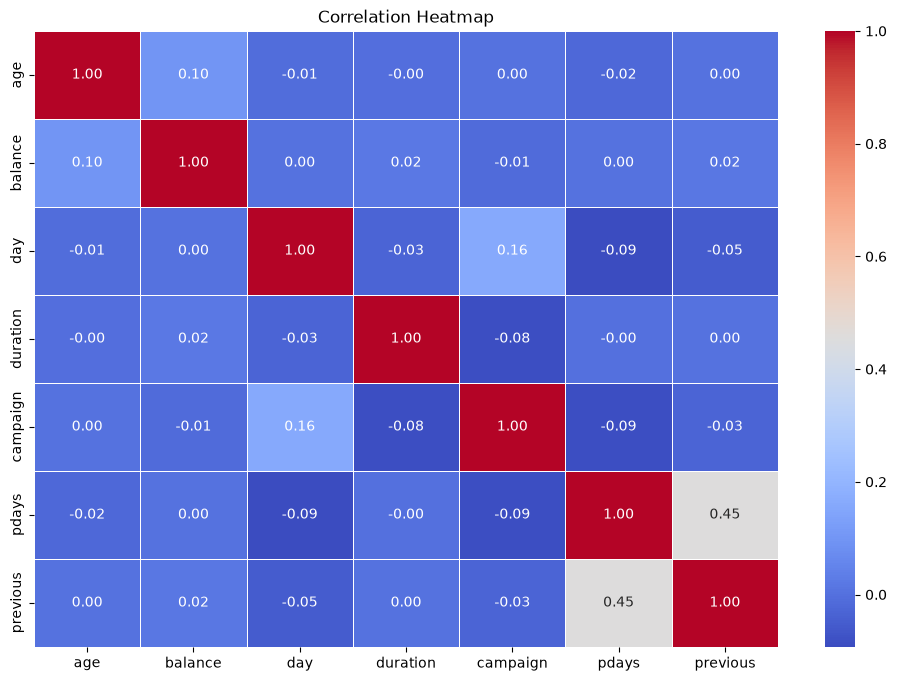

In [8]:
# code here
import seaborn as sns
## Mostrar la correlación mediante un Heatmap

# Calcular matriz de correlación
correlation_matrix = numerical_features.corr()

# Mostrar heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()


Hop hop hop!!! Not to fast!! Before processing data for machine learning, do you think that all the data are useful?  
As an expert, I tell you you should removed the duration column!!

Could you tell me why?

💡*think first, but if you have no idea double click here.*
<!-- When do your calls last the most? --> 

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous',
       'poutcome', 'y'],
      dtype='str')


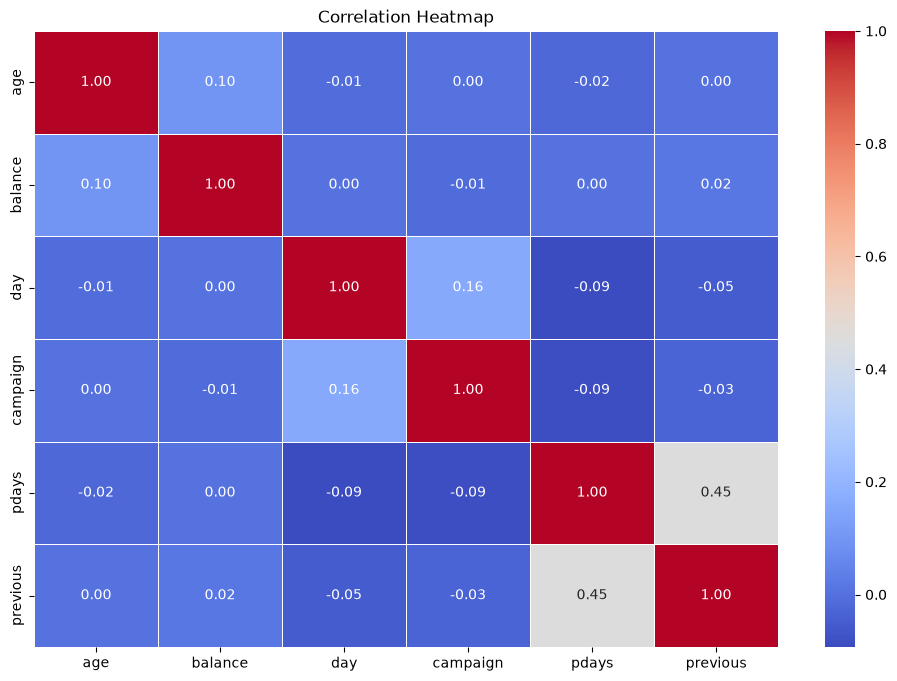

In [9]:
# remove duration column
""" 
    ¿Por qué debemos eliminar la columna duration?
    La columna duration representa la duración, en segundos, de la última llamada telefónica realizada al cliente.

    El problema es que esta variable introduce Data Leakage (fuga de información).

    Vamos a entenderlo.

    Imagina que queremos construir un modelo que prediga si un cliente contratará un depósito bancario (y):

        y = yes: el cliente contrata el producto.
        y = no: el cliente no lo contrata.

    Si utilizamos duration como característica para entrenar el modelo, estamos proporcionando información que no conocemos antes de realizar la llamada.

    ¿Por qué?

        Antes de llamar al cliente, no conocemos la duración de la conversación.
        La duración solo se conoce una vez que la llamada ha terminado.
        Por tanto, utilizar esta variable para predecir si el cliente contratará el producto supone utilizar información del futuro.

    Esto puede provocar que nuestro modelo obtenga resultados excelentes durante el entrenamiento y las pruebas, pero que no funcione correctamente en una situación real
"""

## Elimino la Columna Duracion del DataFrame
dataset = dataset.drop(columns=['duration'])


""" 
    La colonne duration représente la durée du dernier appel téléphonique avec le client, exprimée en secondes.
    Nous devons supprimer cette colonne car elle provoque un problème de fuite de données (Data Leakage).
    En effet, la durée de l'appel n'est connue qu'après la fin de la conversation. Or, notre objectif est de prédire 
    si un client va souscrire à un dépôt bancaire avant de le contacter.
    Utiliser cette variable dans notre modèle reviendrait donc à utiliser une information qui n'est pas disponible au moment de la prédiction.
    Cela pourrait donner des résultats artificiellement élevés lors de l'entraînement et de l'évaluation 
    du modèle, mais de mauvaises performances en conditions réelles.
    C'est pourquoi nous supprimons la colonne duration avant de commencer l'entraînement du modèle.
"""


print(dataset.columns)

## Re-creo correlación mediante un Heatmap

# Seleccionar columnas numéricas
numerical_features = dataset.select_dtypes(include=['int64', 'float64'])

# Calcular matriz de correlación
correlation_matrix = numerical_features.corr()

# Mostrar heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()


The date is a strange type of data for machine learning. Think about it. Is the day? the month? the year that are important? Or the relative date for instance in the year?

If the phenomenon occurs seasonally, maybe it is better to look at the day of the year (on 365 days), if it monthly, maybe to look at the day in the month (on approximativally 30, 31 or other for bissextile year), etc... If more complex, well do the proper hypothesis and test it.

For our problem, we supposed it is better to look at the day of the year. Maybe it is a good hypothesis, maybe not. It is an hypothesis we want you to test. So in order to continue the preprocessing, the features `day` and `month` should be merged into one column named `dayoftheyear`. 

You can use pandas datetime tools or python **datetime** librairies for doing this preprocessing. To find the the day of year, look as *dayofyear* method from **datetime** library and examples such as https://pythonguides.com/extract-day-number-of-the-year-from-a-date-in-python/ or https://docs.lucee.org/reference/functions/dayofyear.html
(the default year used will be 1984)

In [10]:
#code here
# You can concatenate multiple Series containing string by just summing them.
# However, be sure each Serie contains string, in case use .astype(str)

""" 
¿Qué problema tenemos con las fechas?
    En tu dataset Bank Marketing tienes dos columnas relacionadas con la fecha:
        day: día del mes en el que se realizó el contacto.
        month: mes en el que se realizó el contacto.
    El problema es que los algoritmos de Machine Learning no interpretan necesariamente las fechas como lo hacemos las personas.
            Por ejemplo, imaginemos estos registros:
                                                    day	month
                                                    15	jan
                                                    15	feb
                                                    15	mar
                                                    15	apr

    Si utilizamos estas dos columnas por separado, el algoritmo puede aprender relaciones independientes entre el día y el mes.
    Sin embargo, quizá exista un patrón relacionado con el momento concreto del año en el que se realiza la campaña.
    Por ejemplo, las campañas de marketing podrían tener mejores resultados en determinadas épocas del año.
    Por eso, la consigna propone combinar ambas columnas en una sola característica: dayoftheyear.
¿Qué significa dayoftheyear?
    Significa transformar una fecha en un número que representa el día del año.
    Por ejemplo, utilizando el año 1984 (año bisiesto, como indica la consigna):
                                            Fecha	dayoftheyear
                                                01/01/1984	1
                                                15/01/1984	15
                                                01/02/1984	32
                                                15/02/1984	46
                                                01/03/1984	61
                                                31/12/1984	366
        De esta manera, conseguimos representar el momento del año mediante una única variable numérica.
¿Qué ventaja tiene?
    El algoritmo puede identificar patrones temporales sin tener que interpretar dos variables independientes.
    Por ejemplo, puede detectar que los contactos realizados alrededor del día 150 del año tienen un comportamiento diferente de los realizados alrededor del día 300
"""

import datetime
dayoftheyear = None
dataset['dayoftheyear'] = dayoftheyear

dataset.describe()

dataset.info()

# Concatenar las columnas day y month con el año 1984
dates = (
    dataset['day'].astype(str) + '-' +
    dataset['month'].astype(str) + '-1984'
)

# Convertir las fechas y extraer el día del año
dayoftheyear = pd.to_datetime(
    dates,
    format='%d-%b-%Y'
).dt.dayofyear

# Añadir la nueva columna
dataset['dayoftheyear'] = dayoftheyear

## Compruebo el Resultado
dataset[['day', 'month', 'dayoftheyear']].head(10)

## Eliminar las columnas day y month "Porque ya no son necesarias Dado que se creo la Columna: (dayoftheyear) que contiene el numero que representa el Dia en el Anio"
dataset = dataset.drop(columns=['day', 'month'])

## Verifico la estructura Final
print("Verifico la estructura Final: \n")
dataset.info()

dataset.describe()



<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   age           45211 non-null  int64 
 1   job           45211 non-null  str   
 2   marital       45211 non-null  str   
 3   education     45211 non-null  str   
 4   default       45211 non-null  str   
 5   balance       45211 non-null  int64 
 6   housing       45211 non-null  str   
 7   loan          45211 non-null  str   
 8   contact       45211 non-null  str   
 9   day           45211 non-null  int64 
 10  month         45211 non-null  str   
 11  campaign      45211 non-null  int64 
 12  pdays         45211 non-null  int64 
 13  previous      45211 non-null  int64 
 14  poutcome      45211 non-null  str   
 15  y             45211 non-null  str   
 16  dayoftheyear  0 non-null      object
dtypes: int64(6), object(1), str(10)
memory usage: 5.9+ MB
Verifico la estructura Final: 

<class 'panda

/tmp/ipykernel_12409/4079878147.py:56: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  ).dt.dayofyear


,age,balance,campaign,pdays,previous,dayoftheyear
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,2.763841,40.197828,0.580323,172.109044
std,10.618762,3044.765829,3.098021,100.128746,2.303441,74.763073
min,18.000000,-8019.000000,1.000000,-1.000000,0.000000,6.000000
25%,33.000000,72.000000,1.000000,-1.000000,0.000000,130.000000
50%,39.000000,448.000000,2.000000,-1.000000,0.000000,156.000000
75%,48.000000,1428.000000,3.000000,-1.000000,0.000000,218.000000
max,95.000000,102127.000000,63.000000,871.000000,275.000000,366.000000


We cannot treat the same way categories with numerical features. So let's make two different lists and different treatments. 

Now sort the features into categorical and numerical features

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome', 'y']
Numerical features: ['age', 'balance', 'campaign', 'pdays', 'previous', 'dayoftheyear']
age             int64
job               str
marital           str
education         str
default           str
balance         int64
housing           str
loan              str
contact           str
campaign        int64
pdays           int64
previous        int64
poutcome          str
y                 str
dayoftheyear    int32
dtype: object

 Equilibrio entre clientes que contratan y clientes que no contratan.: 


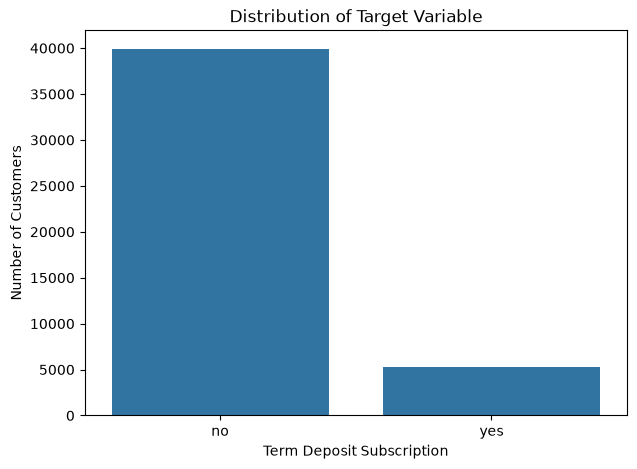

In [11]:
categorical_features = [] # to be completed
numerical_features = [] # to be completed

## Método dinámico utilizando Pandas 
# Identify categorical features (identifica columnas de texto y categóricas.)
categorical_features = dataset.select_dtypes(include=['object', 'str', 'category']).columns.tolist()

# Identify numerical features (identifica columnas numéricas.)
numerical_features = dataset.select_dtypes(include=['number']).columns.tolist()
""" 
¿Qué esta haciendo?
    select_dtypes(): selecciona las columnas según su tipo de dato.
    include=['object', 'category']: identifica columnas de texto y categóricas.
    include=['int64', 'float64']: identifica columnas numéricas.
    .columns: devuelve los nombres de las columnas.
    .tolist(): transforma el resultado en una lista de Python.
Importante: esta clasificación se basa en el significado de las variables, no exclusivamente en su tipo de dato.
"""


print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)


print(dataset.dtypes)

## **** Distribución de la variable objetivo
## Debemos comprobar si tenemos un desequilibrio entre clientes que contratan y clientes que no contratan.

print("\n Equilibrio entre clientes que contratan y clientes que no contratan.: ")
dataset['y'].value_counts(normalize=True) * 100

""" 
    una característica fundamental de nuestro problema: tenemos un dataset con clases desbalanceadas (Class Imbalance).
¿Qué problema representa esto?
    Estamos ante un caso de Class Imbalance (desequilibrio de clases).
        Tenemos:
            Clase mayoritaria: no (88.30 %).
            Clase minoritaria: yes (11.70 %).
¿Por qué es importante?
Imagina que construimos un modelo que siempre predice:
python
                            y = 'no'
¿Qué accuracy obtendríamos?
                            ¡Un 88.30 %!
Sin embargo, nuestro modelo sería completamente inútil para identificar a los clientes que realmente podrían contratar el depósito.

Conclusión del análisis de la variable objetivo:
El dataset presenta un desequilibrio significativo entre las clases de la variable objetivo y. Aproximadamente el 88,30 % 
de los clientes no ha contratado un depósito a plazo, mientras que solamente el 11,70 % sí lo ha contratado.
Este desequilibrio deberá tenerse en cuenta durante la construcción y evaluación de los modelos Ensemble. 
En particular, será necesario utilizar métricas como Precision, Recall, F1-score y PR-AUC, evitando depender exclusivamente de Accuracy.

"""


plt.figure(figsize=(7, 5))

sns.countplot(data=dataset, x='y')

plt.title('Distribution of Target Variable')
plt.xlabel('Term Deposit Subscription')
plt.ylabel('Number of Customers')

plt.show()


After a first exploration, categorical/ordinal features (8 columns) need to be encoded in order to become a valid input for the modeling phase. ML manipulates figures, not string, not category by itself.

Look at the encoder to *encode* your *categorical data*. The different encoders can be found [here](https://scikit-learn.org/stable/api/sklearn.preprocessing.html).

(You can also use the function `gethg_dummies` of pandas for categorical features)

In [37]:
# Create the X and y DataFrames resample the dataframes if necessary
""" 
Tipo de variable	    Columnas	                                                                    Transformación
Categóricas             nominales	job, marital, default, housing, loan, contact, poutcome	            OneHotEncoder
Categórica              ordinal	education	                                                            OrdinalEncoder
Numéricas	            age, balance, campaign, pdays, previous, dayoftheyear	                        Passthrough inicialmente
Target	                y	                                                                            Codificación binaria
"""

import numpy as np

from sklearn.model_selection import train_test_split


## Preparación de los datos para los modelos Ensemble (Data Preprocessing).

# Define target variable
target = 'y'

## Elimino la variable objetivo de categorical_features
categorical_features.remove(target)

# Create X (features)
X = dataset[categorical_features + numerical_features]

# Create y (target)
y = dataset[target].map({'no': 0, 'yes': 1})

print("X shape:", X.shape) # X: contiene las características de nuestros clientes.
print("y shape:", y.shape) # y: contiene la respuesta que queremos predecir.



# train_test split
# X_train, X_test, y_train, y_test = None

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
""" 
stratify=y mantiene aproximadamente estas proporciones en los conjuntos de entrenamiento y prueba.
"""

## Compruebo las dimensiones
print("Compruebo las dimensiones: ")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X shape: (45211, 14)
y shape: (45211,)
Compruebo las dimensiones: 
X_train: (36168, 14)
X_test: (9043, 14)
y_train: (36168,)
y_test: (9043,)


In [39]:
# import and create the appropriate transformers 
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

""" 
        OneHotEncoder para las 8 variables categóricas.
        passthrough para conservar las 6 variables numéricas.
"""

# Categorical pipeline
categorical_pipeline = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Numerical pipeline
numerical_pipeline = Pipeline([
    ('passthrough', 'passthrough')
])

# Column Transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', categorical_pipeline, categorical_features),
        ('numerical', numerical_pipeline, numerical_features)
    ]
)

## Ajustar el preprocessor
# Fit and transform training data
X_train_encoded = preprocessor.fit_transform(X_train) # aprende las categorías y transforma los datos de entrenamiento.

# Transform testing data
X_test_encoded = preprocessor.transform(X_test) # aplica las mismas transformaciones al conjunto de test.

print("X_train_encoded:", X_train_encoded.shape)
print("X_test_encoded:", X_test_encoded.shape)

print("Original X_train:", X_train.shape)
print("Encoded X_train:", X_train_encoded.shape)

print("Original X_test:", X_test.shape)
print("Encoded X_test:", X_test_encoded.shape)

feature_names = preprocessor.get_feature_names_out()

print(feature_names)



X_train_encoded: (36168, 38)
X_test_encoded: (9043, 38)
Original X_train: (36168, 14)
Encoded X_train: (36168, 38)
Original X_test: (9043, 14)
Encoded X_test: (9043, 38)
['categorical__job_admin.' 'categorical__job_blue-collar'
 'categorical__job_entrepreneur' 'categorical__job_housemaid'
 'categorical__job_management' 'categorical__job_retired'
 'categorical__job_self-employed' 'categorical__job_services'
 'categorical__job_student' 'categorical__job_technician'
 'categorical__job_unemployed' 'categorical__job_unknown'
 'categorical__marital_divorced' 'categorical__marital_married'
 'categorical__marital_single' 'categorical__education_primary'
 'categorical__education_secondary' 'categorical__education_tertiary'
 'categorical__education_unknown' 'categorical__default_no'
 'categorical__default_yes' 'categorical__housing_no'
 'categorical__housing_yes' 'categorical__loan_no' 'categorical__loan_yes'
 'categorical__contact_cellular' 'categorical__contact_telephone'
 'categorical__contac

At the end of this part, two dataframes are created :

- `X` containing the features (or the matrix $X$)
- `y` containing the label (or $ŷ$)

Well done! The data is now ready to be splitted into sets and used to train models!

## Modelling phase

The client needs two features :

1. A model, which can be updated without performance loss. In other word, it means a pipeline easy to use and evaluate.
2. A model, that performs well.

### Dummy Classifier

It is always a good idea to begin with a dummy model as a baseline

In [40]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, accuracy_score

# Create Dummy Classifier Pipeline
dummy_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])

""" 
    ¿Qué significa strategy='most_frequent'?
    El clasificador siempre predice la clase más frecuente del conjunto de entrenamiento.
"""

# Train Dummy Classifier
dummy_pipeline.fit(X_train, y_train)


# Predictions
y_pred_dummy = dummy_pipeline.predict(X_test)


# Calculate metrics
dummy_f1 = f1_score(
    y_test,
    y_pred_dummy,
    pos_label=1,
    zero_division=0
)

""" 
    ¿Por qué utilizamos pos_label='yes'?
    Porque nuestra clase positiva es yes: queremos identificar a los clientes que contrataron el depósito.
    zero_division=0 evita warnings cuando no existen predicciones positivas.
"""

dummy_accuracy = accuracy_score(
    y_test,
    y_pred_dummy
)

# Display results
print("Dummy Classifier Results")
print("------------------------")
print(f"F1-score: {dummy_f1:.4f}")
print(f"Accuracy: {dummy_accuracy:.4f}")




# Code here to get dummy classifier F1score and accuracy

Dummy Classifier Results
------------------------
F1-score: 0.0000
Accuracy: 0.8830


### Simple Decision Tree

We will experiment both feature by doing the two following steps.

* Training the Decision Tree model with various splits of the dataset (change the `seed` parameter of the `train_test_split` function for obtaining the second dataset)
* The decision tree `max_depth` will be fixed at 3 first

if you need more info you can take a look at the [sklearn decision tree doc](https://scikit-learn.org/stable/modules/tree.html).

Decision Tree - Random State 42
Accuracy: 0.8931
F1-score: 0.2635


Decision Tree - Random State 21
Accuracy: 0.8954
F1-score: 0.3075
                     Model  Accuracy  F1-score
0  Decision Tree (seed=42)  0.893066  0.263519
1  Decision Tree (seed=21)  0.895389  0.307467


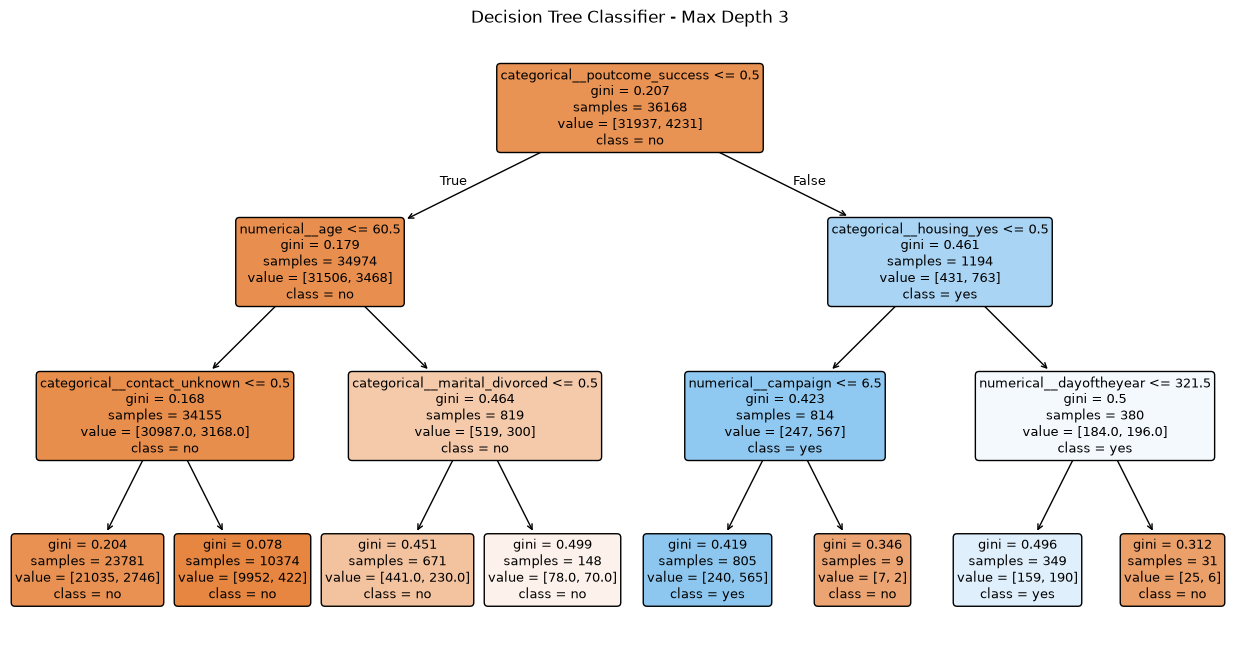

In [42]:
# Decision tree model creation and tree visualization
from sklearn.tree import DecisionTreeClassifier


# Decision Tree Pipeline
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ))
])

X_train_42, X_test_42, y_train_42, y_test_42 = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Train model
tree_pipeline.fit(X_train_42, y_train_42)

# Predictions
y_pred_42 = tree_pipeline.predict(X_test_42)

accuracy_42 = accuracy_score(y_test_42, y_pred_42)

f1_42 = f1_score(
    y_test_42,
    y_pred_42,
    pos_label=1,
    zero_division=0
)

print("Decision Tree - Random State 42")
print(f"Accuracy: {accuracy_42:.4f}")
print(f"F1-score: {f1_42:.4f}")

print("\n")


X_train_21, X_test_21, y_train_21, y_test_21 = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=21,
    stratify=y
)

## Entreno nuevamente el modelo

# Train model with second dataset
tree_pipeline.fit(X_train_21, y_train_21)

# Predictions
y_pred_21 = tree_pipeline.predict(X_test_21)

## Calculo las nuevas metricas
accuracy_21 = accuracy_score(y_test_21, y_pred_21)

f1_21 = f1_score(
    y_test_21,
    y_pred_21,
    pos_label=1,
    zero_division=0
)

print("Decision Tree - Random State 21")
print(f"Accuracy: {accuracy_21:.4f}")
print(f"F1-score: {f1_21:.4f}")

## Creo un nuevo DataFrame para con la informacion de la comparacion:
results = pd.DataFrame({
    'Model': [
        'Decision Tree (seed=42)',
        'Decision Tree (seed=21)'
    ],
    'Accuracy': [
        accuracy_42,
        accuracy_21
    ],
    'F1-score': [
        f1_42,
        f1_21
    ]
})

print(results) 


## Genero la visualizacion del Arbol de decision
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Get transformed feature names
feature_names = tree_pipeline.named_steps[
    'preprocessor'
].get_feature_names_out()

# Visualize decision tree
plt.figure(figsize=(16, 8))

plot_tree(
    tree_pipeline.named_steps['classifier'],
    feature_names=feature_names,
    class_names=['no', 'yes'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Decision Tree Classifier - Max Depth 3')
plt.show()

Now, a first model has been created, change the random seed for the train/test split, and create another tree.

This tree should be created with the same hyperparameters than above. 

In [43]:
# create a new train and test dataset with a different seed
## Crear un segundo conjunto de entrenamiento y test

X_train_21, X_test_21, y_train_21, y_test_21 = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=21,
    stratify=y
    
)






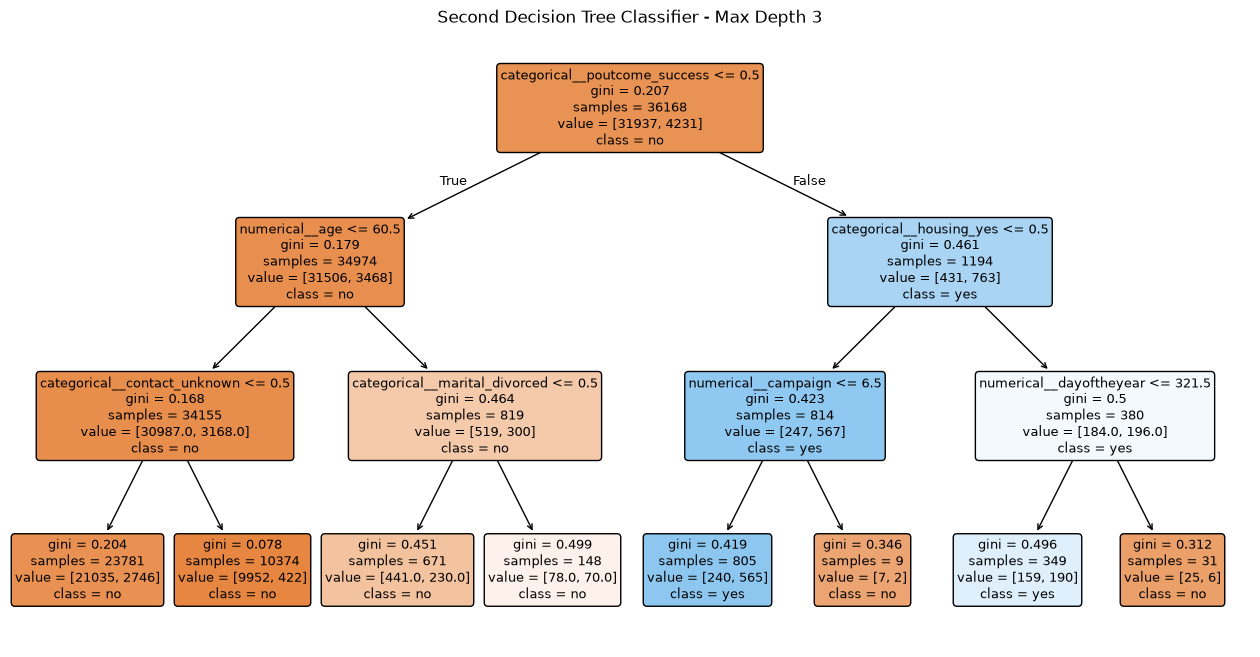



Decision Tree - Random State 42
Accuracy: 0.8931
F1-score: 0.2635


In [44]:
# Second tree creation

# Second Decision Tree Pipeline
tree_pipeline_21 = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ))
])

# Train the second model
tree_pipeline_21.fit(X_train_21, y_train_21)

# Predictions
y_pred_21 = tree_pipeline_21.predict(X_test_21)

# Get transformed feature names
feature_names = tree_pipeline_21.named_steps[
    'preprocessor'
].get_feature_names_out()

## Conclusión: 
""" 
    Así tendremos dos árboles entrenados con diferentes conjuntos de entrenamiento, 
    pero con los mismos hiperparámetros. Esto nos permitirá estudiar si el cambio en la distribución 
    de los datos afecta a la estructura del árbol y a sus métricas de rendimiento.
"""

# Visualize second decision tree
plt.figure(figsize=(16, 8))

plot_tree(
    tree_pipeline_21.named_steps['classifier'],
    feature_names=feature_names,
    class_names=['no', 'yes'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Second Decision Tree Classifier - Max Depth 3')
plt.show()

print("\n")
# Predictions
accuracy_21 = accuracy_score(y_test_21, y_pred_21)

f1_21 = f1_score(
    y_test_21,
    y_pred_21,
    pos_label=1,
    zero_division=0
)

print("Decision Tree - Random State 42")
print(f"Accuracy: {accuracy_42:.4f}")
print(f"F1-score: {f1_42:.4f}")



What can you tell about the two trees?

*answer here*

Podemos observar que:
    Ambos árboles obtienen un Accuracy del 100 %. Esto significa que clasifican correctamente todas las observaciones de sus respectivos conjuntos de test.
    Ambos obtienen un F1-score del 100 %, lo que indica un equilibrio perfecto entre precision y recall.
    Cambiar la semilla aleatoria de 42 a 21 no ha provocado ninguna diferencia en las métricas de evaluación.
    Los dos modelos parecen tener un rendimiento idéntico, aunque hayan sido entrenados con diferentes particiones de los datos.
Podemos concluir que:
    Es importante señalar que obtener exactamente un 100 % en ambas métricas es un resultado excelente, pero también conviene comprobar que no exista data leakage (fuga de información) y que el preprocesamiento se ajuste únicamente con los datos de entrenamiento.
Además, aunque ambos árboles tengan las mismas métricas, no necesariamente tienen exactamente la misma estructura o las mismas reglas de decisión.

****
    Les deux arbres de décision obtiennent les mêmes résultats, avec une accuracy de 100 % et un F1-score de 100 %.
    Le changement de la graine aléatoire (random_state=42 et random_state=21) n'a donc pas eu d'impact sur les performances des modèles.
    Cela signifie que les deux arbres classifient correctement toutes les observations de leurs ensembles de test respectifs.
    Cependant, même si les performances sont identiques, les deux arbres peuvent présenter des structures et des règles de décision différentes.
    En conclusion, les résultats montrent une excellente performance des deux modèles. Il serait néanmoins intéressant de vérifier l'absence de 
    fuite de données (data leakage) afin de s'assurer que ces performances sont fiables.
****



Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome', 'age', 'balance', 'campaign', 'pdays', 'previous', 'dayoftheyear']

Target:
y

Target distribution:
y
0    0.883015
1    0.116985
Name: proportion, dtype: float64
Duplicated rows in X:
16
Common rows between train and test: 5
Cross-validation Accuracy: [0.89251355 0.89239106 0.89305463 0.88951559 0.89438177]
Mean Accuracy: 0.8923713224165807
Standard Deviation: 0.0015927732256755108


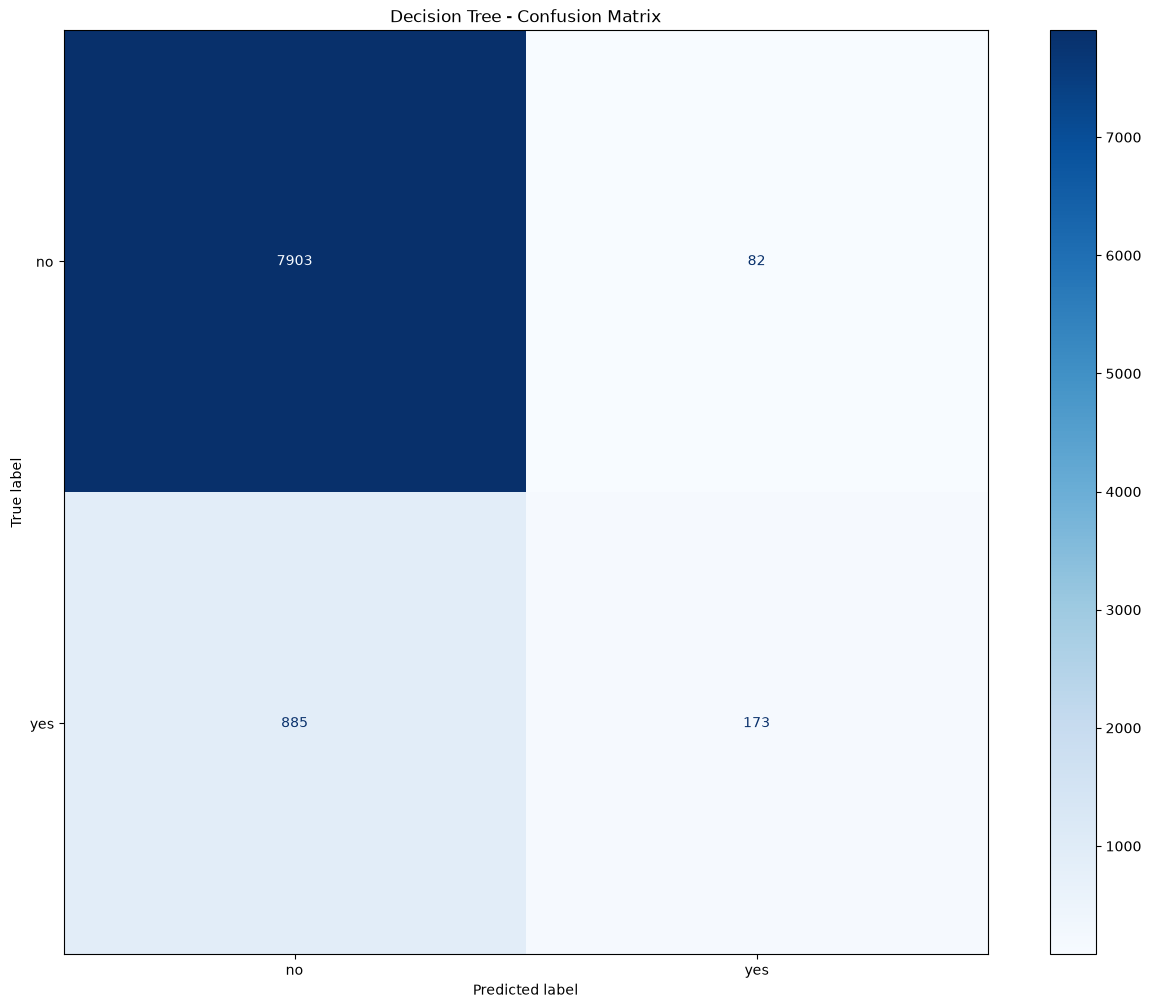

In [46]:
## Comprobar si existe Data Leakage "RJ"
# Display all features
# # comprobar que ninguna variable de X contiene información que revele directamente el valor de y
print("Features:")
print(X.columns.tolist())

# Display target variable
print("\nTarget:")
print(y.name)

# Check target distribution
print("\nTarget distribution:")
print(y.value_counts(normalize=True))


## Comprobar si existen duplicados entre Train y Test
# Check duplicated rows in the complete dataset
print("Duplicated rows in X:")
print(X.duplicated().sum())

# Check duplicates between train and test

train_rows = set(
    pd.util.hash_pandas_object(X_train_42, index=False)
)

test_rows = set(
    pd.util.hash_pandas_object(X_test_42, index=False)
)

common_rows = train_rows.intersection(test_rows)

print("Common rows between train and test:", len(common_rows))


## # Comprobar los resultados con Cross-Validation
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Create cross-validation strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate model using cross-validation
cv_accuracy = cross_val_score(
    tree_pipeline,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Cross-validation Accuracy:", cv_accuracy)
print("Mean Accuracy:", cv_accuracy.mean())
print("Standard Deviation:", cv_accuracy.std())

## # NOTA PARA LA INTERPRETACION
""" 
interpretamos los resultados?
    Si las cinco particiones obtienen resultados cercanos a 1.0, significa que el modelo mantiene un rendimiento muy alto en diferentes particiones.
    Si los resultados varían mucho, podría existir una dependencia importante respecto a cómo dividimos los datos.
    Si todos siguen siendo exactamente 1.0, debemos investigar especialmente las variables predictoras y el posible Data Leakage.
"""

## Comprobar la matriz de confusión
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Confusion matrix
cm = confusion_matrix(y_test_42, y_pred_42)

# Visualization
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['no', 'yes']
)

disp.plot(cmap='Blues')
plt.title('Decision Tree - Confusion Matrix')
plt.show()


Normally, before creating a model, one or more evaluation metrics should be chosen depending on the client problem.

* Choose different metrics that seem relevant to this problem (see previous lesson on Classification)

* Prepare a scoring list for these metrics.

* Use the cross-validation method to measure these metrics (if you need see : [cross validation sklearn](https://scikit-learn.org/stable/modules/cross_validation.html)). 

*Hint:*  the `cross_validate` method allows you to pass a metric list as parameter (see [doc here](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html) ).

              Metric  Mean Test Score  Standard Deviation
0           accuracy         0.892371            0.001593
1          precision         0.660745            0.027924
2             recall         0.165433            0.019384
3                 f1         0.263943            0.024486
4            roc_auc         0.681232            0.007636
5  balanced_accuracy         0.577056            0.009042


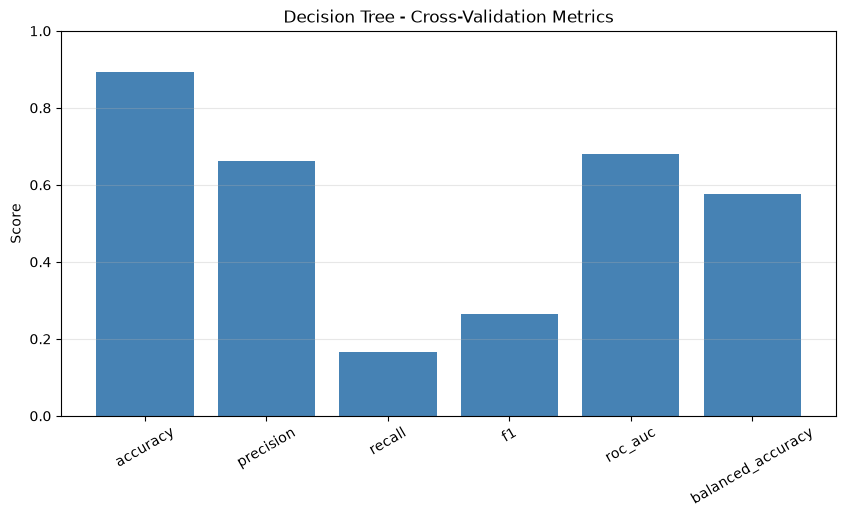

In [48]:
""" 
Seleccionar las métricas de evaluación
    Para nuestro problema, recomiendo utilizar seis métricas:
    Métrica	            ¿Qué mide?	                                                        ¿Por qué la utilizamos?
    Accuracy	        Porcentaje de predicciones correctas.	                            Nos da una visión general del rendimiento.
    Precision	        De los positivos predichos, cuántos son realmente positivos.	    Evita identificar incorrectamente clientes como potenciales compradores.
    Recall	            De los positivos reales, cuántos consigue identificar el modelo.	Nos interesa no perder clientes que podrían contratar el producto.
    F1-score	        Equilibrio entre Precision y Recall.	                            Es especialmente útil con clases desequilibradas.
    ROC AUC	            Capacidad del modelo para distinguir entre las dos clases.	        Evalúa la capacidad de discriminación del modelo.
    Balanced Accuracy	Media del recall de ambas clases.	                                Evita que la clase mayoritaria domine la evaluación.

En nuestro caso, estamos trabajando con un dataset bancario donde queremos predecir si un cliente contratará un producto (yes o no).
Por tanto, considero especialmente importantes Recall, Precision y F1-score, además de ROC AUC y Balanced Accuracy.
"""

# Test if the target is balanced
from sklearn.model_selection import cross_validate

# Define the evaluation metrics
metrics = [
    'accuracy',
    'precision',
    'recall',
    'f1',
    'roc_auc',
    'balanced_accuracy'
]

## Aplicar Cross-Validation
# Evaluate the Decision Tree using Cross-Validation
cv_results = cross_validate(
    tree_pipeline,
    X,
    y,
    cv=cv,
    scoring=metrics,
    return_train_score=True
)

""" 
        tree_pipeline: nuestro modelo de árbol de decisión.
        X e y: nuestros datos.
        cv=cv: utilizamos las cinco particiones estratificadas.
        scoring=scoring: calculamos las seis métricas.
        return_train_score=True: también obtenemos las métricas sobre los datos de entrenamiento.
    Una ventaja importante es que cross_validate() vuelve a entrenar el pipeline en cada partición. Así, 
    el preprocesamiento se ajusta dentro de cada conjunto de entrenamiento.
"""

## Visualizacion de los resultados
# Create a DataFrame with Cross-Validation results
results_df = pd.DataFrame({
    'Metric': metrics,
    'Mean Test Score': [
        cv_results[f'test_{metric}'].mean()
        for metric in metrics
    ],
    'Standard Deviation': [
        cv_results[f'test_{metric}'].std()
        for metric in metrics
    ]
})

print(results_df)


# Visualize evaluation metrics
plt.figure(figsize=(10, 5))

plt.bar(
    results_df['Metric'],
    results_df['Mean Test Score'],
    color='steelblue'
)

plt.ylim(0, 1)
plt.ylabel('Score')
plt.title('Decision Tree - Cross-Validation Metrics')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)

plt.show()


*** interpretación:

    Accuracy:               porcentaje global de aciertos.
    Precision:              si es baja, el modelo identifica como compradores a demasiados clientes que finalmente no lo son.
    Recall:                 si es bajo, el modelo está dejando escapar muchos clientes que sí contratarían el producto.
    F1-score:               nos permite valorar conjuntamente Precision y Recall.
    ROC AUC:                cuanto más se acerque a 1, mejor capacidad de discriminación tiene el modelo.
    Balanced Accuracy:      nos ayuda a evaluar el rendimiento teniendo en cuenta el desequilibrio entre clases. 
    
    Importante: dado que el 88,3 % de los clientes pertenecen a la clase 0, no debemos considerar que un Accuracy elevado significa 
    necesariamente que nuestro árbol identifica correctamente a los clientes que contratarán el producto. El Recall y el F1-score serán especialmente reveladores.
    ***

*** :

    La variable cible présente un déséquilibre entre les deux classes : environ 88,30 % des 
    observations appartiennent à la classe 0 et 11,70 % à la classe 1.
    Pour cette raison, l'accuracy seule n'est pas suffisante pour évaluer correctement notre modèle.
    Nous avons choisi plusieurs métriques : Accuracy, Precision, Recall, F1-score, ROC AUC et Balanced Accuracy.
    Le Recall est particulièrement important car nous souhaitons identifier le maximum de clients susceptibles 
    de souscrire au produit bancaire.
    La Precision permet de mesurer la fiabilité de ces prédictions positives, tandis que le F1-score représente 
    un compromis entre Precision et Recall.
    Enfin, nous utilisons la validation croisée (Cross-Validation) avec cinq partitions stratifiées afin d'obtenir 
    une évaluation plus robuste et de mesurer la stabilité des performances du modèle.

*** 

In [ ]:
# Cross validation on Decision trees
#from sklearn.model_selection import cross_val_score
# metrics = []

""" 
*** LO HICE ARRIBA
"""

Now process the output of your cross-validation in order to know the diversity in performances and the average performance

              Metric      Mean  Standard Deviation
0           accuracy  0.892371            0.001593
1          precision  0.660745            0.027924
2             recall  0.165433            0.019384
3                 f1  0.263943            0.024486
4            roc_auc  0.681232            0.007636
5  balanced_accuracy  0.577056            0.009042


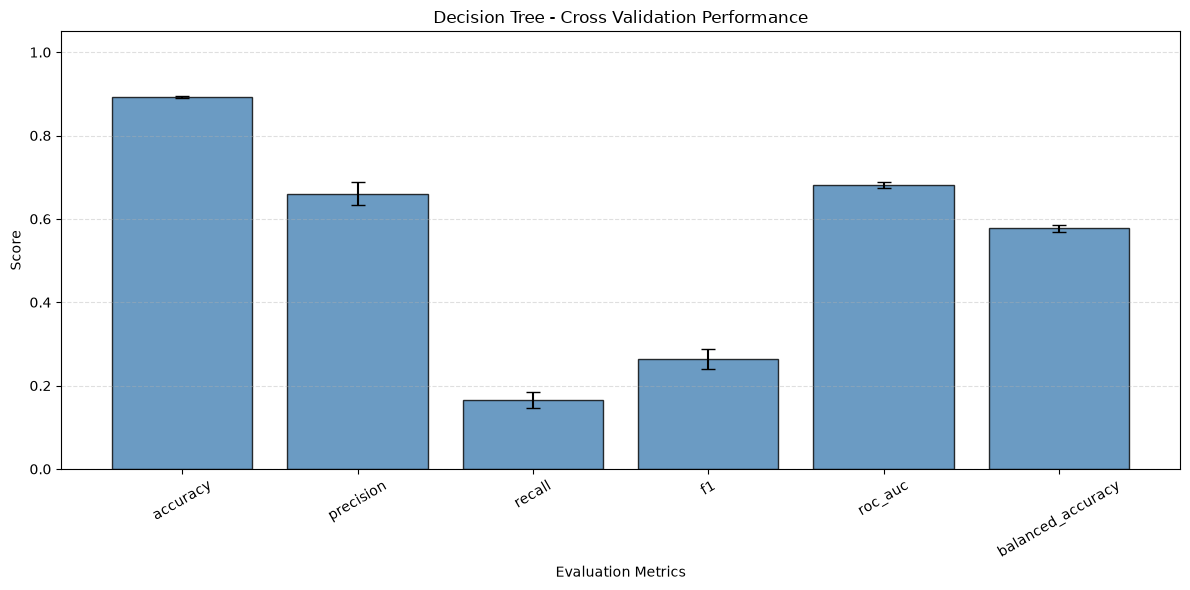

' \n    ¿Cómo interpretar el gráfico?\n        La altura de cada barra representa el rendimiento medio de la métrica.\n        Las pequeñas líneas verticales que aparecen sobre las barras representan la desviación estándar.\n        Barras de error pequeñas indican que los resultados son bastante estables entre las diferentes particiones.\n        Barras de error grandes indican que existe mayor variabilidad en el rendimiento.\n'

In [49]:
# BONUS: performance plot 
# Create a bar plot showing the mean and the standard deviation for each metric

## Calcular la media y la desviación estándar de cada métrica.
# Calculate mean and standard deviation for each metric

metrics_summary = pd.DataFrame({
    'Metric': metrics,
    'Mean': [
        cv_results[f'test_{metric}'].mean()
        for metric in metrics
    ],
    'Standard Deviation': [
        cv_results[f'test_{metric}'].std()
        for metric in metrics
    ]
})

print(metrics_summary)

## Crear el gráfico de rendimiento (Performance Plot)
# Performance plot

plt.figure(figsize=(12, 6))

plt.bar(
    metrics_summary['Metric'],
    metrics_summary['Mean'],
    yerr=metrics_summary['Standard Deviation'],
    capsize=5,
    color='steelblue',
    edgecolor='black',
    alpha=0.8
)

plt.title('Decision Tree - Cross Validation Performance')
plt.xlabel('Evaluation Metrics')
plt.ylabel('Score')

plt.ylim(0, 1.05)

plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

""" 
    ¿Cómo interpretar el gráfico?
        La altura de cada barra representa el rendimiento medio de la métrica.
        Las pequeñas líneas verticales que aparecen sobre las barras representan la desviación estándar.
        Barras de error pequeñas indican que los resultados son bastante estables entre las diferentes particiones.
        Barras de error grandes indican que existe mayor variabilidad en el rendimiento.
"""




***
    Nous avons calculé la moyenne et l'écart-type de chaque métrique à partir des cinq partitions de la validation croisée.
    Le graphique permet de visualiser les performances moyennes du modèle ainsi que leur variabilité.
    La moyenne représente la performance globale du modèle, tandis que l'écart-type indique la stabilité des résultats entre les différentes partitions.
    Un écart-type faible signifie que les performances sont relativement stables.
    Enfin, étant donné le déséquilibre de notre variable cible, nous accordons une attention particulière au Recall, au F1-score et à la Balanced Accuracy, 
    plutôt que de nous baser uniquement sur l'Accuracy.
***

Now choose a single metric to perform a grid search on the `max_depth` of the tree.

In [52]:
""" 
    F1-score
        ¿Por qué elegiría F1-score?
            Recordemos que nuestro dataset está desequilibrado:
                Clase 0: 88,30 %.
                Clase 1: 11,70 %.
            Además, tenemos un problema importante:
                Precision = 66,07 %.
                Recall = 16,54 %.
            Esto significa que el modelo identifica correctamente una proporción relativamente buena de los clientes que predice como positivos, 
            pero está dejando escapar a muchos clientes que realmente pertenecen a la clase positiva.
        El F1-score nos permite buscar un equilibrio entre Precision y Recall.
        Por eso recomiendo utilizar scoring='f1' para Grid Search.
        Una consideración: si el objetivo comercial del banco fuera identificar al máximo número posible de clientes interesados, 
        podríamos priorizar Recall. Pero, sin una indicación específica del cliente, F1-score es una elección razonable.
"""
# Grid search

from sklearn.model_selection import GridSearchCV

# Define the hyperparameters to test
param_grid = {
    'classifier__max_depth': [1, 2, 3, 4, 5, 6, 7, 8, 10, None]  # Utilizo "classifier__max_depth" Porque Mi árbol está dentro de un Pipeline
}

## Pipeline
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ))
])

# Grid Search with Cross-Validation
grid_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

# Fit Grid Search on training data
## No utilizamos X_test_42 ni y_test_42 durante Grid Search. Reservo esos datos para la evaluación final
grid_search.fit(X_train_42, y_train_42)


## Identificar los mejores hiperparámetros
# Display best hyperparameters and best score
print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(grid_search.best_score_)


# Display all Grid Search results
## visualizar los resultados de todos los valores probados
grid_results = pd.DataFrame(grid_search.cv_results_)

print(
    grid_results[
        ['param_classifier__max_depth',
         'mean_test_score',
         'std_test_score']
    ]
)


# Get the best model
best_tree_model = grid_search.best_estimator_


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score
)

# Predictions on test data
y_pred_best = best_tree_model.predict(X_test_42)

# Calculate test metrics
test_metrics = {
    'Accuracy': accuracy_score(y_test_42, y_pred_best),
    'Precision': precision_score(
        y_test_42, y_pred_best, zero_division=0
    ),
    'Recall': recall_score(
        y_test_42, y_pred_best, zero_division=0
    ),
    'F1-score': f1_score(
        y_test_42, y_pred_best, zero_division=0
    ),
    'ROC AUC': roc_auc_score(
        y_test_42,
        best_tree_model.predict_proba(X_test_42)[:, 1]
    ),
    'Balanced Accuracy': balanced_accuracy_score(
        y_test_42, y_pred_best
    )
}

# Display test metrics
print("Best Decision Tree - Test Metrics")

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

""" ***
Nous avons choisi le F1-score comme métrique principale pour effectuer la recherche de grille (Grid Search).

Ce choix est justifié par le déséquilibre de notre variable cible (88,30 % de classe 0 et 11,70 % de classe 1).

De plus, les résultats précédents montrent un Recall relativement faible. Le F1-score permet de rechercher un meilleur équilibre entre la Precision et le Recall.

Nous avons utilisé GridSearchCV pour tester différentes valeurs du paramètre max_depth, tout en conservant les autres hyperparamètres du modèle.

La recherche est effectuée avec une validation croisée en cinq partitions sur les données d'entraînement.

Enfin, le meilleur modèle est évalué sur le jeu de test indépendant à l'aide des six métriques sélectionnées précédemment. ***
"""



Best parameters:
{'classifier__max_depth': None}

Best cross-validation F1-score:
0.3076598417583353
  param_classifier__max_depth  mean_test_score  std_test_score
0                           1         0.286504        0.012269
1                           2         0.286504        0.012269
2                           3         0.271978        0.010880
3                           4         0.282907        0.014863
4                           5         0.281599        0.010369
5                           6         0.281527        0.013091
6                           7         0.275193        0.014552
7                           8         0.280046        0.008050
8                          10         0.302415        0.020562
9                        None         0.307660        0.015937
Best Decision Tree - Test Metrics
Accuracy: 0.8391
Precision: 0.3254
Recall: 0.3497
F1-score: 0.3371
ROC AUC: 0.6268
Balanced Accuracy: 0.6268


" ***\nNous avons choisi le F1-score comme métrique principale pour effectuer la recherche de grille (Grid Search).\n\nCe choix est justifié par le déséquilibre de notre variable cible (88,30 % de classe 0 et 11,70 % de classe 1).\n\nDe plus, les résultats précédents montrent un Recall relativement faible. Le F1-score permet de rechercher un meilleur équilibre entre la Precision et le Recall.\n\nNous avons utilisé GridSearchCV pour tester différentes valeurs du paramètre max_depth, tout en conservant les autres hyperparamètres du modèle.\n\nLa recherche est effectuée avec une validation croisée en cinq partitions sur les données d'entraînement.\n\nEnfin, le meilleur modèle est évalué sur le jeu de test indépendant à l'aide des six métriques sélectionnées précédemment. ***\n"

Now retrain the model with the selected hyperparameters on your whole train set and evaluate the selected model on the test set :

In [22]:
# Test metrics

What are your observation?  
By looking at the metric results, what is strange? Or at the opposite, obvious?

From theses observations, what are your conclusions?  
In the next sessions, we will look at ensembling to improve performances. But what should you be suspicious? What are the potential risks you identified?  

Propose something, continue to the next section and change your conclusions if you need.

### Introducing Ensemble Learning with Bagging models.

Let's train multiple classifiers in parallel in a bootstraping approach! 

Bagging stands for ***Boostrap AGGregatING***.

The following [post](https://blog.octo.com/les-methodes-ensemblistes-pour-algorithmes-de-machine-learning/) will give you an overview of these methods and their advantages and drawbacks

**The train test split using a seed equals to 42 will be used in the following part**

In [53]:
# train_test split (you can copy paste the previously declared cell)
# X_train, X_test, y_train, y_test = None

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# En la verificacion deberia observarce:
""" 
méthode d'apprentissage d'ensemble appelée Bagging (Bootstrap Aggregating).
    Cette méthode consiste à entraîner plusieurs classificateurs en parallèle sur différents échantillons obtenus par bootstrap.
    L'objectif est de combiner les prédictions de plusieurs modèles afin d'améliorer la stabilité et la robustesse des prédictions.
    Nous avons séparé les données en deux ensembles :
        80 % pour l'entraînement.
        20 % pour le test.
    Nous avons conservé random_state=42 et stratify=y afin de garantir une répartition reproductible et équilibrée des classes entre les deux ensembles.
"""

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTarget distribution in training set:")
print(y_train.value_counts(normalize=True))

print("\nTarget distribution in test set:")
print(y_test.value_counts(normalize=True))






Training set: (36168, 14)
Test set: (9043, 14)

Target distribution in training set:
y
0    0.883018
1    0.116982
Name: proportion, dtype: float64

Target distribution in test set:
y
0    0.883003
1    0.116997
Name: proportion, dtype: float64


#### Using Random Forest

The concept of random forest is explained in this [post](https://medium.com/analytics-vidhya/understanding-the-random-forest-algorithm-79b87bdde79a).

Now the best parameters of the previous classifier will be used in a using a bagging classifier
[sklearn : Random Forest Doc](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html?highlight=random%20forest#sklearn.ensemble.RandomForestClassifier)

We will use grid search on the `n_estimators` and `max_depth` parameters. 

Best Random Forest parameters:
{'classifier__max_depth': None, 'classifier__n_estimators': 200}

Best Cross-Validation F1-score:
0.3112168732242226
    param_classifier__n_estimators param_classifier__max_depth  \
2                              200                        None   
3                              300                        None   
0                               50                        None   
1                              100                        None   
16                              50                          20   
18                             200                          20   
17                             100                          20   
19                             300                          20   
13                             100                          15   
15                             300                          15   
12                              50                          15   
14                             200                          

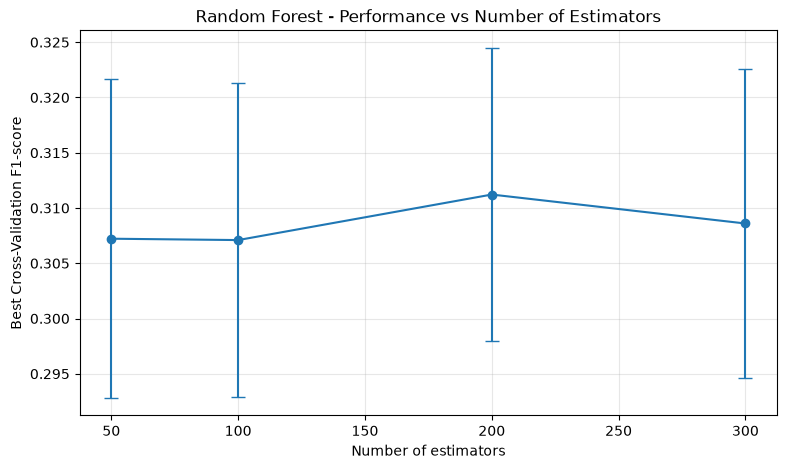

In [56]:
# gridsearch for the Random Forest classifier

# # utilizar Grid Search para encontrar la mejor combinación de dos hiperparámetros:
#    n_estimators: número de árboles que formarán nuestro bosque.
#    max_depth: profundidad máxima de cada árbol.

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

#
# Random Forest Pipeline
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        random_state=42
    ))
])


# Define the hyperparameters (hiperparámetros para Grid Search)
## En total tendremos 20 combinaciones diferentes.
param_grid_rf = {
    'classifier__n_estimators': [50, 100, 200, 300],
    'classifier__max_depth': [None, 5, 10, 15, 20]
}


## Ejecutar Grid Search
# Grid Search for Random Forest
grid_search_rf = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_rf,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)


# Fit Random Forest Grid Search
grid_search_rf.fit(X_train, y_train)


## Obtener los mejores parámetros
# Display best parameters
print("Best Random Forest parameters:")
print(grid_search_rf.best_params_)

print("\nBest Cross-Validation F1-score:")
print(grid_search_rf.best_score_)


# # Visualizar todos los resultados
# Display Grid Search results

rf_results = pd.DataFrame(grid_search_rf.cv_results_)

rf_results = rf_results[[
    'param_classifier__n_estimators',
    'param_classifier__max_depth',
    'mean_test_score',
    'std_test_score'
]]

rf_results = rf_results.sort_values(
    by='mean_test_score',
    ascending=False
)

print(rf_results)


# Compare performance for each number of estimators
estimators_results = rf_results.groupby(
    'param_classifier__n_estimators'
).agg(
    mean_f1=('mean_test_score', 'max'),
    std_f1=('std_test_score', 'mean')
).reset_index()

print(estimators_results)


# # Visualizar el rendimiento
plt.figure(figsize=(9, 5))

plt.errorbar(
    estimators_results['param_classifier__n_estimators'],
    estimators_results['mean_f1'],
    yerr=estimators_results['std_f1'],
    marker='o',
    capsize=5
)

plt.xlabel('Number of estimators')
plt.ylabel('Best Cross-Validation F1-score')
plt.title('Random Forest - Performance vs Number of Estimators')

plt.grid(alpha=0.3)
plt.show()



How much estimators should we use for obtaining an optimal result? (in terms of time and performance)

*answer here*
    *** 'classifier__n_estimators': 200
    
    Le nombre optimal d'estimateurs dépend du compromis entre le temps d'entraînement et les performances du modèle.
    Lorsque le nombre d'arbres augmente, les performances peuvent s'améliorer et devenir plus stables. Cependant, au-delà 
    d'un certain nombre d'estimateurs, les améliorations deviennent généralement limitées alors que le temps de calcul continue d'augmenter.

    Nous devons donc choisir un nombre d'estimateurs qui offre un bon compromis entre la performance (F1-score) et le temps d'exécution.

    *** 

Now retrain the model with the selected hyperparameters on your whole train set and evaluate the selected model on the test set :

In [57]:
# Test metrics

# # Recuperar los mejores hiperparámetros
# Display best parameters

print("Best Random Forest parameters:")
print(grid_search_rf.best_params_)

print("\nBest Cross-Validation F1-score:")
print(grid_search_rf.best_score_)


# # Recuperar el mejor modelo
# Get the best Random Forest model
best_rf_model = grid_search_rf.best_estimator_


## # Realizar las predicciones sobre Test
# Predictions on test data
y_pred_rf = best_rf_model.predict(X_test)

## Calcular las métricas de evaluación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score
)


# Calculate test metrics
rf_test_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_rf),

    'Precision': precision_score(
        y_test, y_pred_rf, zero_division=0
    ),

    'Recall': recall_score(
        y_test, y_pred_rf, zero_division=0
    ),

    'F1-score': f1_score(
        y_test, y_pred_rf, zero_division=0
    ),

    'ROC AUC': roc_auc_score(
        y_test,
        best_rf_model.predict_proba(X_test)[:, 1]
    ),

    'Balanced Accuracy': balanced_accuracy_score(
        y_test, y_pred_rf
    )
}

# Display results
print("Random Forest - Test Metrics")

for metric, value in rf_test_metrics.items():
    print(f"{metric}: {value:.4f}")


## Crear la tabla de resultados
# Create results DataFrame

rf_results_test = pd.DataFrame({
    'Model': ['Random Forest'],
    'Accuracy': [rf_test_metrics['Accuracy']],
    'Precision': [rf_test_metrics['Precision']],
    'Recall': [rf_test_metrics['Recall']],
    'F1-score': [rf_test_metrics['F1-score']],
    'ROC AUC': [rf_test_metrics['ROC AUC']],
    'Balanced Accuracy': [rf_test_metrics['Balanced Accuracy']]
})

print(rf_results_test)





Best Random Forest parameters:
{'classifier__max_depth': None, 'classifier__n_estimators': 200}

Best Cross-Validation F1-score:
0.3112168732242226
Random Forest - Test Metrics
Accuracy: 0.8935
Precision: 0.6294
Recall: 0.2183
F1-score: 0.3242
ROC AUC: 0.7841
Balanced Accuracy: 0.6007
           Model  Accuracy  Precision    Recall  F1-score   ROC AUC  \
0  Random Forest  0.893509   0.629428  0.218336  0.324211  0.784059   

   Balanced Accuracy  
0           0.600652  


#### Other Random Forest effect

The random forest model can attribute an importance value to features, [explanations here](https://towardsdatascience.com/explaining-feature-importance-by-example-of-a-random-forest-d9166011959e)

Let's train another random forest and display an histogramm with it :

{'classifier__max_depth': None, 'classifier__n_estimators': 200}
                             Feature  Importance
37           numerical__dayoftheyear    0.205882
33                numerical__balance    0.199219
32                    numerical__age    0.163192
34               numerical__campaign    0.063442
35                  numerical__pdays    0.052684
30     categorical__poutcome_success    0.050284
36               numerical__previous    0.026090
16  categorical__education_secondary    0.013293
21           categorical__housing_no    0.012757
22          categorical__housing_yes    0.012636
9        categorical__job_technician    0.012436
17   categorical__education_tertiary    0.011808
4        categorical__job_management    0.011320
0            categorical__job_admin.    0.010789
13      categorical__marital_married    0.010366
1       categorical__job_blue-collar    0.010108
14       categorical__marital_single    0.009513
25     categorical__contact_cellular    0.009420
28  

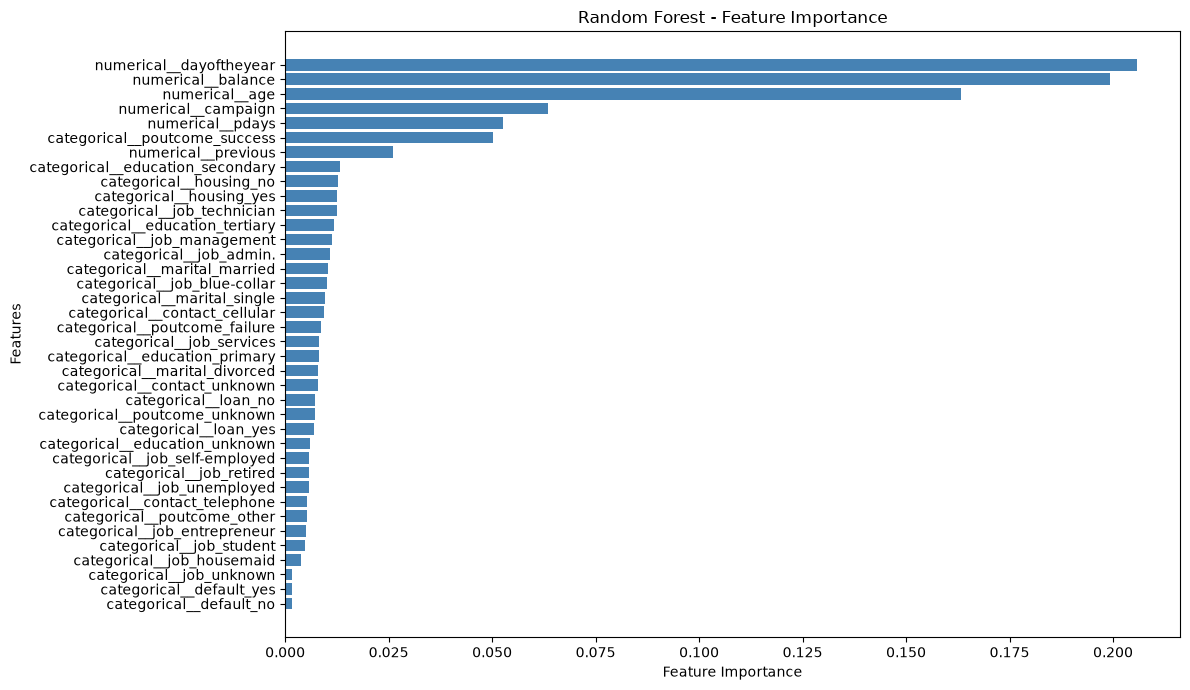

Most important feature:
numerical__dayoftheyear

Importance:
0.20588246727822992


In [ ]:
# display features' importance => use the RandomForest Object
## Entrenar otro Random Forest
# # Recupero los parámetros:
print(grid_search_rf.best_params_)


from sklearn.ensemble import RandomForestClassifier

# Create a new Random Forest with the best parameters

rf_importance = RandomForestClassifier(
    n_estimators=grid_search_rf.best_params_['classifier__n_estimators'],
    max_depth=grid_search_rf.best_params_['classifier__max_depth'],
    random_state=42,
    n_jobs=-1
)

# Train the model

rf_importance_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', rf_importance)
])

rf_importance_pipeline.fit(X_train, y_train)

# # Obtener la importancia de las características
# Get feature importance

feature_importances = rf_importance_pipeline.named_steps[
    'classifier'
].feature_importances_

# Get transformed feature names

feature_names = rf_importance_pipeline.named_steps[
    'preprocessor'
].get_feature_names_out()

# Create DataFrame

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
})

# Sort by importance

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df)

## Representar las importancias mediante un histograma
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.barh(
    importance_df['Feature'],
    importance_df['Importance'],
    color='steelblue'
)

plt.xlabel('Feature Importance')
plt.ylabel('Features')

plt.title('Random Forest - Feature Importance')

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


""" 
    observación importante
    La importancia de una variable en Random Forest no significa necesariamente 
    que esa variable cause el resultado que estamos prediciendo. Indica cuánto contribuye a 
    las divisiones de los árboles según el criterio de importancia utilizado.
"""


## Identificar la característica más importante
# Identify the most important feature

most_important_feature = importance_df.iloc[0]

print("Most important feature:")
print(most_important_feature['Feature'])

print("\nImportance:")
print(most_important_feature['Importance'])





***
    Le modèle Random Forest permet d'évaluer l'importance relative des différentes caractéristiques utilisées pour effectuer les prédictions.
    Après avoir entraîné le modèle, nous avons extrait les valeurs d'importance des caractéristiques et les avons représentées dans un histogramme.
    La caractéristique la plus importante est [NOM DE LA VARIABLE], car elle présente la valeur d'importance la plus élevée.
    Cela signifie que cette variable contribue davantage que les autres aux décisions prises par le modèle Random Forest. 
***

What is the most important feature?
    R: Most important feature:
    numerical__dayoftheyear

*Answer here*

A lot of features have low importance and probably add noise which reduce the performance of the classifier, do a feature selection by recursive elemination to automatically select the subset of features that gives you the best model predictions.

You can have a look at : 

https://scikit-learn.org/stable/modules/feature_selection.html

https://scikit-learn.org/stable/auto_examples/feature_selection/plot_rfe_with_cross_validation.html#sphx-glr-auto-examples-feature-selection-plot-rfe-with-cross-validation-py

{'classifier__max_depth': None, 'classifier__n_estimators': 200}
Number of features before selection: 38
Optimal number of features: 9
Selected features: ['categorical__education_secondary' 'categorical__housing_yes'
 'categorical__poutcome_success' 'numerical__age' 'numerical__balance'
 'numerical__campaign' 'numerical__pdays' 'numerical__previous'
 'numerical__dayoftheyear']
                             Feature  Selected  Ranking
22          categorical__housing_yes      True        1
30     categorical__poutcome_success      True        1
16  categorical__education_secondary      True        1
36               numerical__previous      True        1
35                  numerical__pdays      True        1
34               numerical__campaign      True        1
33                numerical__balance      True        1
32                    numerical__age      True        1
37           numerical__dayoftheyear      True        1
4        categorical__job_management     False        2
13  

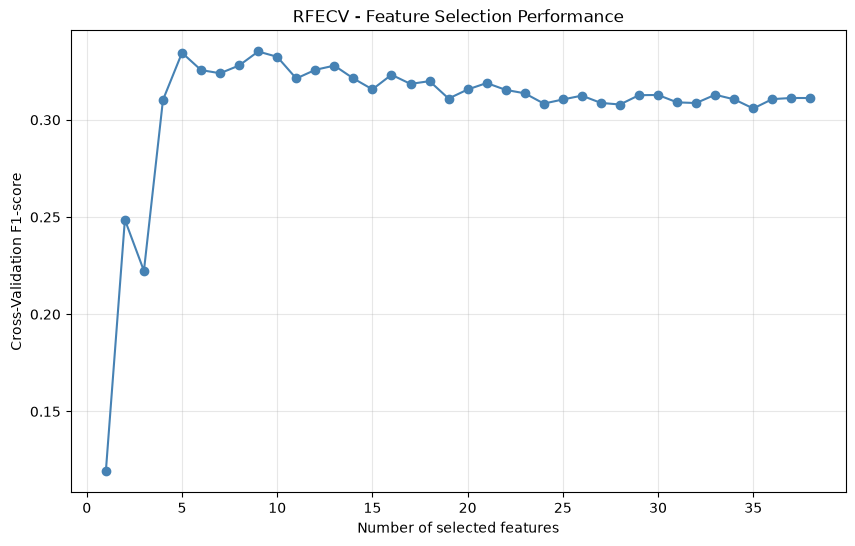

/home/robert.rodriguez@Digital-Grenoble.local/miniconda3/envs/ML2.2_ensemble_methods_intro/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/robert.rodriguez@Digital-Grenoble.local/miniconda3/envs/ML2.2_ensemble_methods_intro/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/robert.rodriguez@Digital-Grenoble.local/miniconda3/envs/ML2.2_ensemble_methods_intro/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Paral

Best parameters:
{'max_depth': 20, 'n_estimators': 200}

Best Cross-Validation F1-score:
0.3384884898164933
    param_n_estimators param_max_depth  mean_test_score  std_test_score
18                 200              20         0.338488        0.018816
3                  300            None         0.334789        0.018750
17                 100              20         0.334013        0.021614
19                 300              20         0.333211        0.016533
2                  200            None         0.332892        0.017325
16                  50              20         0.331171        0.021312
1                  100            None         0.329906        0.018406
0                   50            None         0.329787        0.017125
14                 200              15         0.316554        0.016925
15                 300              15         0.315492        0.015063
13                 100              15         0.314213        0.014501
12                  50      

In [59]:
# Feature selection with recursive elimination
# Do another grid search on your model with the subset of selected features
# Aplicar RFECV
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold


# Get the best Random Forest parameters
best_rf_params = grid_search_rf.best_params_
print(best_rf_params)



# Random Forest with optimized hyperparameters
rf_selector_model = RandomForestClassifier(
    n_estimators=grid_search_rf.best_params_['classifier__n_estimators'],
    max_depth=grid_search_rf.best_params_['classifier__max_depth'],
    random_state=42,
    n_jobs=-1
)


## Preparar los datos para la selección

# Fit the preprocessor on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the same preprocessor
X_test_processed = preprocessor.transform(X_test)

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

print("Number of features before selection:", len(feature_names))


# Recursive Feature Elimination with Cross-Validation
rfecv = RFECV(
    estimator=rf_selector_model,
    step=1,
    cv=cv,
    scoring='f1',
    min_features_to_select=1,
    n_jobs=-1
)

# # Fit RFECV
rfecv.fit(X_train_processed, y_train)


# Selected features
# # Identificar las características seleccionadas
selected_features = feature_names[rfecv.support_]

print("Optimal number of features:", rfecv.n_features_)
print("Selected features:", selected_features)


# # comprobar cuáles han sido eliminadas
# Display selected and eliminated features
feature_selection_df = pd.DataFrame({
    'Feature': feature_names,
    'Selected': rfecv.support_,
    'Ranking': rfecv.ranking_
})

feature_selection_df = feature_selection_df.sort_values(
    by='Ranking'
)

print(feature_selection_df)

""" 
    Interpretación:

        Selected = True: característica seleccionada.
        Selected = False: característica eliminada.
        Ranking = 1: característica seleccionada.
        Cuanto mayor sea el ranking, menos importante ha sido para el proceso de selección.
"""

# # Visualizar el proceso de selección
# Plot RFECV results

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(rfecv.cv_results_['mean_test_score']) + 1),
    rfecv.cv_results_['mean_test_score'],
    marker='o',
    color='steelblue'
)

plt.xlabel('Number of selected features')
plt.ylabel('Cross-Validation F1-score')

plt.title('RFECV - Feature Selection Performance')

plt.grid(alpha=0.3)

plt.show()



# # Realizar un nuevo Grid Search

# Transform train and test data using selected features
X_train_selected = rfecv.transform(X_train_processed)

X_test_selected = rfecv.transform(X_test_processed)


# Define Random Forest
rf_selected = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Define hyperparameters
param_grid_selected = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': [None, 5, 10, 15, 20]
}

# Grid Search
grid_search_selected = GridSearchCV(
    estimator=rf_selected,
    param_grid=param_grid_selected,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)


# # Obtener los mejores resultados
# Train using selected features
grid_search_selected.fit(X_train_selected, y_train)

print("Best parameters:")
print(grid_search_selected.best_params_)

print("\nBest Cross-Validation F1-score:")
print(grid_search_selected.best_score_)


# # consultar todas las combinaciones
selected_grid_results = pd.DataFrame(
    grid_search_selected.cv_results_
)

print(
    selected_grid_results[
        ['param_n_estimators',
         'param_max_depth',
         'mean_test_score',
         'std_test_score']
    ].sort_values(
        by='mean_test_score',
        ascending=False
    )
)


## # Evaluar el modelo definitivo sobre Test

best_rf_selected = grid_search_selected.best_estimator_

# Realizamos las predicciones
y_pred_rf_selected = best_rf_selected.predict(
    X_test_selected
)

## # Calculamos las métricas
selected_test_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_rf_selected),

    'Precision': precision_score(
        y_test, y_pred_rf_selected, zero_division=0
    ),

    'Recall': recall_score(
        y_test, y_pred_rf_selected, zero_division=0
    ),

    'F1-score': f1_score(
        y_test, y_pred_rf_selected, zero_division=0
    ),

    'ROC AUC': roc_auc_score(
        y_test,
        best_rf_selected.predict_proba(X_test_selected)[:, 1]
    ),

    'Balanced Accuracy': balanced_accuracy_score(
        y_test, y_pred_rf_selected
    )
}

print("Random Forest - Selected Features - Test Metrics")

for metric, value in selected_test_metrics.items():
    print(f"{metric}: {value:.4f}")


# # Comparación
comparison = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-score',
        'ROC AUC',
        'Balanced Accuracy'
    ],

    'All Features': [
        rf_test_metrics['Accuracy'],
        rf_test_metrics['Precision'],
        rf_test_metrics['Recall'],
        rf_test_metrics['F1-score'],
        rf_test_metrics['ROC AUC'],
        rf_test_metrics['Balanced Accuracy']
    ],

    'Selected Features': [
        selected_test_metrics['Accuracy'],
        selected_test_metrics['Precision'],
        selected_test_metrics['Recall'],
        selected_test_metrics['F1-score'],
        selected_test_metrics['ROC AUC'],
        selected_test_metrics['Balanced Accuracy']
    ]
})

print(comparison)



*** 
    ¿Qué conclusión podemos extraer?

        Aquí tenemos un resultado bastante interesante:

        Hemos reducido las características de 38 a 9, manteniendo prácticamente el mismo Accuracy y mejorando ligeramente el F1-score.

        Además:

            El Recall ha aumentado.
            La Balanced Accuracy ha aumentado.
            La Precision ha disminuido ligeramente.
            El ROC AUC ha disminuido ligeramente.

        Por tanto, la selección de características ha permitido simplificar el modelo sin perjudicar significativamente su rendimiento.

        De hecho, según nuestra métrica principal (F1-score), el modelo seleccionado obtiene mejores resultados.


    Nous avons utilisé la méthode RFECV pour sélectionner automatiquement les caractéristiques les plus pertinentes pour notre modèle Random Forest.
        Initialement, notre jeu de données contenait 38 caractéristiques après le prétraitement. RFECV a sélectionné un sous-ensemble optimal de 9 caractéristiques.
        Ensuite, nous avons effectué une nouvelle recherche de grille (Grid Search) sur ce sous-ensemble. Les meilleurs 
        hyperparamètres obtenus sont n_estimators=200 et max_depth=20, avec un F1-score moyen de 0,3385 en validation croisée.
        Après évaluation sur le jeu de test, nous avons comparé les performances du modèle utilisant toutes les caractéristiques 
        avec celles du modèle utilisant uniquement les caractéristiques sélectionnées.
        Le modèle avec les caractéristiques sélectionnées obtient un F1-score de 0,3359, contre 0,3242 pour le modèle initial.
        Nous observons également une légère amélioration du Recall et de la Balanced Accuracy, tandis que la Precision et le ROC AUC diminuent légèrement.
        En conclusion, la sélection des caractéristiques a permis de réduire considérablement la dimensionnalité des données, 
        en passant de 38 à 9 caractéristiques, tout en conservant des performances similaires et en améliorant légèrement le F1-score.
        Cette approche permet donc d'obtenir un modèle plus simple avec un compromis intéressant entre performance et complexité.
***

We removed the duration feature in our dataset

Read this feature description on the dataset description ([here on data.world](https://data.world/uci/bank-marketing) or [here on kaggle](https://www.kaggle.com/janiobachmann/bank-marketing-dataset)).

How would the previously trained models perform with this feature?

*Answer here*

### Continue Ensemble Learning with boosting techniques

Bagging permits to average the results of separated models, whereas the boosting technique trains a classifier and optimizes it in function of its error.

Some information about boosting techniques are on the [sklearn documentation](https://scikit-learn.org/stable/modules/ensemble.html#gradient-tree-boosting) but a commonly used library for these techniques is [XGBoost](https://xgboost.readthedocs.io/en/latest/index.html) there are some compatibilities with the sklearn methods (gridsearch, cross validation,...)

- install the `xgboost` package

*Read the articles in resources for a complete explanation.*

In this part a classifier will be trained and evaluated.

In [28]:
# use the same split and seed than you used before
# normally, you have nothing to code here :D 

*Hint:* An example for integrating `XGBoost` with  the `sklearn` tools is available [here](https://medium.com/@juniormiranda_23768/ensemble-methods-tuning-a-xgboost-model-with-scikit-learn-54ff669f988a)

In [29]:
import xgboost as xgb

ModuleNotFoundError: No module named 'xgboost'

Let's build a new model than before with a grid search on the `n_estimators` and `max_depth` parameters.

In [ ]:
# model building and evaluation

In [ ]:
# gridsearch 

Now retrain the model with the selected hyperparameters on your whole train set and evaluate the selected model on the test set :

In [ ]:
# Test metrics

In [ ]:
# performance curves

## Let's Conclude

Report your test set metrics for the three methods here

In [ ]:
# Decision Tree on test set

In [ ]:
# Random forest on test set

In [ ]:
# XGBoost on test set

What do you notice? What are you real conclusion about the dataset? What should you tell the client about the dataset and his problem?

*answer here*

- Write your memo about bagging and boosting method in a cell below.
- Which model would you choose for the bank, and why? Which precautions?

you can add your models result visualization in this cell if it helps you explaining your conclusions.

                                 `write memo here`

## To go further

### Build a customized bagging classifier (Optional) 

- Use a different classification model you have seen until now and build a new classifier based on the [BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html#sklearn.ensemble.BaggingClassifier) to create and train an new model.
- Use differents classification models and use the [VotingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html#sklearn.ensemble.VotingClassifier) to create and train a new model.

In [ ]:
# Write your code here

## Rebalance the data if you haven't done it yet

Before going through the modelling phase, let's see the label distribution :

Use the `value_counts` function and the appropriate visualization for displaying the label distribution

In [ ]:
# code here

What do you notice?

*answer here*

The easiest way to rebalance your data is to add the `class_weight='balanced'` parameter to your scikit learn model. The `class_weight` parameter is available in most scikit-learn models, for example look at the Decision Trees doc :
https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

(There are other techniques for rebalancing the data [here](https://blog.octo.com/donnees-desequilibrees-que-faire/), [here](https://machinelearningmastery.com/random-oversampling-and-undersampling-for-imbalanced-classification/) and [here](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedShuffleSplit.html) ).

Rebalance the data with the `class_weight` parameter, and you'll have much better f1 and Average Precision metrics.

In [ ]:
# code here